# 08 — Lựa chọn mô hình và báo cáo cuối
Tổng hợp trực tiếp chín ứng viên từ các notebook 01–07 và 09–10. Chọn mô hình chỉ bằng Validation F2; sau đó mới mở Test để báo cáo và vẽ so sánh mô tả giống cấu trúc của giảng viên.

## 0. Chuẩn bị môi trường và quy tắc báo cáo
Chạy 01–07, 09 và 10 trước notebook này. Không dùng kết quả Test để đổi feature, siêu tham số, trọng số hoặc threshold.

In [1]:
from pathlib import Path
import json, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
    roc_auc_score, average_precision_score, confusion_matrix)
from securaai_ml.data import load_training_data
from securaai_ml.modeling import decision_scores
from securaai_ml.schema import MODEL_FEATURES, TARGET_COLUMN, GROUP_COLUMN
from securaai_ml.train import temporal_train_validation_test
ROOT=Path.cwd().parent if Path.cwd().name=='notebooks' else Path.cwd()
EXPERIMENTS=ROOT/'reports'/'notebook_experiments'
data,audit=load_training_data(ROOT/'data'/'raw')
train,validation,test=temporal_train_validation_test(data)
X_validation,y_validation=validation.loc[:,MODEL_FEATURES],validation[TARGET_COLUMN]
X_test,y_test=test.loc[:,MODEL_FEATURES],test[TARGET_COLUMN]
SEED=42
print(audit)

DatasetAudit(rows=94365, malicious=58530, benign=35835, groups=36, invalid_timestamps=0)


## 1. Kiểm tra giao thức và artifact
Bảy ứng viên theo chuỗi giảng viên cùng hai mô hình mở rộng Linear SVM và Logistic Regression đều tham gia một phép so sánh thống nhất.

In [2]:
main_specs=[
 ('01_decision_tree','Decision Tree','model'),('02_naive_bayes','Naive Bayes','model'),
 ('03_rule_based','Rule-Based','rule'),('04_bagging','Bagging','model'),
 ('05_random_forest','Random Forest','model'),('06_adaboost','AdaBoost','model'),
 ('07_soft_voting','Soft Voting','model'),('09_linear_svm','Linear SVM','model'),
 ('10_logistic_regression','Logistic Regression','model')]
missing=[slug for slug,_,kind in main_specs if not (EXPERIMENTS/f'{slug}.json').exists() or (kind=='model' and not (EXPERIMENTS/f'{slug}.joblib').exists())]
assert not missing, f'Chạy lại notebook để tạo artifact còn thiếu: {missing}'
records={slug:json.loads((EXPERIMENTS/f'{slug}.json').read_text(encoding='utf-8')) for slug,_,_ in main_specs}
split_hashes={r['split_hash'] for r in records.values()}
assert len(split_hashes)==1, 'Artifact không cùng data split; phải chạy lại các notebook mô hình.'
print('Artifacts hợp lệ:',len(main_specs),'mô hình | split hash:',next(iter(split_hashes))[:16])

Artifacts hợp lệ: 9 mô hình | split hash: c20123f0928c7b1d


## 2. Chuẩn hóa metric từ schema mới
Schema v2 tách rõ Validation mặc định, Validation ngưỡng khóa và Test ngưỡng khóa. Hàm fallback chỉ giúp đọc artifact cũ trong lúc chuyển đổi.

In [3]:
def metrics_at(record,stage):
    if stage=='validation':
        return record.get('validation_locked_threshold',record.get('validation'))
    return record.get('test_locked_threshold',record.get('test'))
def rule_score(frame):
    return (2*frame['has_command_line']+frame['has_parent_command_line']+2*frame['has_hashes']+frame['has_target_file']+frame['has_source_ip']+frame['event_status'].isin(['failure','failed','denied']).astype(int)).to_numpy(float)
def measured_metrics(y,score,pred):
    return {'accuracy':accuracy_score(y,pred),'precision':precision_score(y,pred,zero_division=0),'recall':recall_score(y,pred,zero_division=0),'f1':f1_score(y,pred,zero_division=0),'f2':fbeta_score(y,pred,beta=2,zero_division=0),'roc_auc':roc_auc_score(y,score),'average_precision':average_precision_score(y,score)}
rows=[]; fitted_models={}
for slug,label,kind in main_specs:
    record=records[slug]; threshold=float(record['locked_threshold'])
    if kind=='rule': score=rule_score(X_validation)
    else:
        fitted_models[slug]=joblib.load(EXPERIMENTS/f'{slug}.joblib')
        score=decision_scores(fitted_models[slug],X_validation)
    pred=(score>=threshold).astype(int); metric=measured_metrics(y_validation,score,pred)
    rows.append({'slug':slug,'model':label,'threshold':threshold,'cv_f2':record.get('cv_best_f2',np.nan),**metric})
comparison=pd.DataFrame(rows).sort_values(['f2','recall','precision'],ascending=False).reset_index(drop=True)
display(comparison[['model','threshold','cv_f2','accuracy','precision','recall','f1','f2','roc_auc','average_precision']])

,model,threshold,cv_f2,accuracy,precision,recall,f1,f2,roc_auc,average_precision
0,Soft Voting,1.802349e-01,NaN,0.999058,0.998285,1.000000,0.999142,0.999656,0.999940,0.999949
1,Random Forest,2.340351e-01,0.988712,0.998414,0.997653,0.999457,0.998554,0.999096,0.999955,0.999962
2,AdaBoost,4.625739e-01,0.983958,0.998216,0.998282,0.998463,0.998372,0.998427,0.999898,0.999910
3,Linear SVM,-7.513870e-01,0.987068,0.998315,0.998553,0.998372,0.998463,0.998408,0.999714,0.999797
4,Logistic Regression,8.344741e-02,0.982063,0.998067,0.998282,0.998191,0.998236,0.998209,0.999750,0.999815
5,Bagging,1.000000e-02,0.986001,0.990831,0.997165,0.986073,0.991588,0.988272,0.992827,0.993410
6,Decision Tree,1.453831e-01,0.985678,0.980967,0.999158,0.966088,0.982345,0.972526,0.982679,0.984129
7,Naive Bayes,7.153922e-43,0.009476,0.882633,0.825810,0.995931,0.902927,0.956521,0.969572,0.976096
8,Rule-Based,1.000000e+00,NaN,0.959159,0.999902,0.925574,0.961304,0.939542,0.962730,0.966313


## 3. So sánh metric trên Validation
F2 là tiêu chí chốt vì bài toán SOC ưu tiên giảm FN, nhưng vẫn báo cáo Precision để thể hiện tải cảnh báo giả.

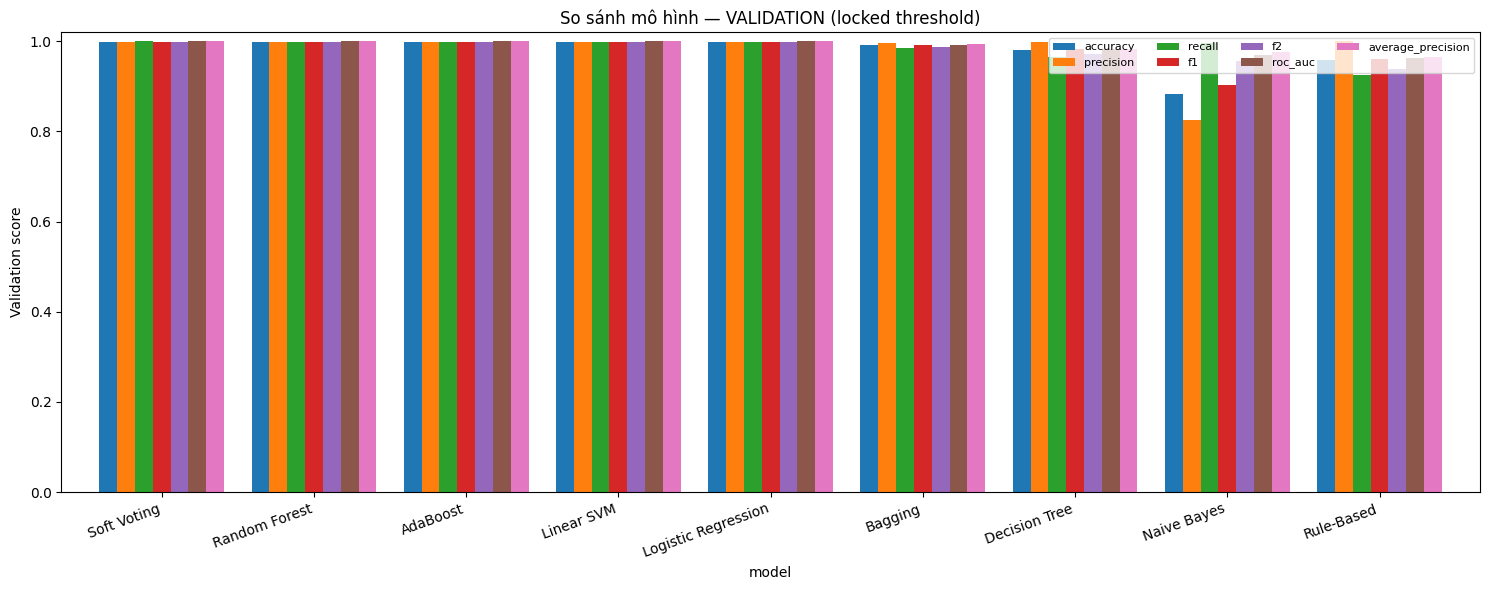

In [4]:
metrics=['accuracy','precision','recall','f1','f2','roc_auc','average_precision']
ax=comparison.set_index('model')[metrics].plot.bar(figsize=(15,6),ylim=(0,1.02),width=.82)
ax.set_ylabel('Validation score'); ax.set_title('So sánh mô hình — VALIDATION (locked threshold)'); plt.xticks(rotation=20,ha='right'); plt.legend(ncol=4,fontsize=8); plt.tight_layout(); plt.show()

## 4. Chọn và khóa mô hình bằng Validation
Mô hình đứng đầu F2 được chọn trước khi đọc bất kỳ kết quả Test nào trong notebook này. Nếu hòa, ưu tiên Recall rồi Precision.

In [5]:
selected=comparison.iloc[0]
selected_slug=selected['slug']; selected_label=selected['model']; selected_record=records[selected_slug]
print('Mô hình được chọn:',selected_label)
print('Validation F2:',selected['f2'],'| threshold:',selected['threshold'])
display(selected.to_frame('selected_on_validation'))

Mô hình được chọn: Soft Voting
Validation F2: 0.9996564754379939 | threshold: 0.1802348975914406


,selected_on_validation
slug,07_soft_voting
model,Soft Voting
threshold,0.180235
cv_f2,NaN
accuracy,0.999058
precision,0.998285
recall,1.0
f1,0.999142
f2,0.999656
roc_auc,0.99994


## 5. Tạo score Test cho các đường ROC/PR
Đây là so sánh mô tả sau khi lựa chọn đã khóa, giống notebook giảng viên. Không dùng biểu đồ Test để đổi người thắng.

In [6]:
results={}
for slug,label,kind in main_specs:
    record=records[slug]; threshold=float(record['locked_threshold'])
    score=rule_score(X_test) if kind=='rule' else decision_scores(fitted_models[slug],X_test)
    pred=(score>=threshold).astype(int)
    results[slug]={'label':label,'score':score,'pred':pred,'threshold':threshold}
print('Đã tính score Test cho',len(results),'ứng viên; quyết định lựa chọn vẫn là',selected_label)

Đã tính score Test cho 9 ứng viên; quyết định lựa chọn vẫn là Soft Voting


## 6. ROC và Precision–Recall của tất cả mô hình
Số trong ngoặc là ROC-AUC/AP. Đường gạch PR là tỷ lệ MALICIOUS_APT trong Test, không phải một hằng số cố định.

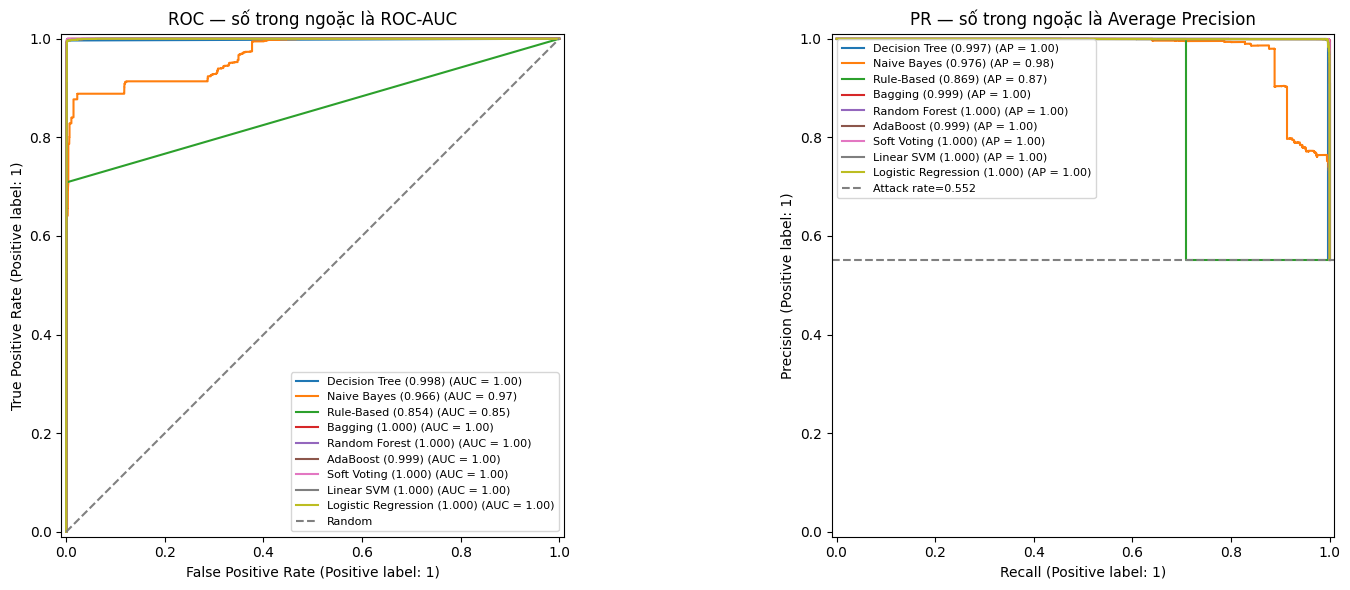

In [7]:
fig,axes=plt.subplots(1,2,figsize=(16,6))
for slug,label,_ in main_specs:
    score=results[slug]['score']
    auc=roc_auc_score(y_test,score); ap=average_precision_score(y_test,score)
    RocCurveDisplay.from_predictions(y_test,score,name=f'{label} ({auc:.3f})',ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test,score,name=f'{label} ({ap:.3f})',ax=axes[1])
axes[0].plot([0,1],[0,1],'--',color='gray',label='Random'); axes[0].set_title('ROC — số trong ngoặc là ROC-AUC')
axes[1].axhline(float(y_test.mean()),ls='--',color='gray',label=f'Attack rate={y_test.mean():.3f}'); axes[1].set_title('PR — số trong ngoặc là Average Precision')
for ax in axes: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. Bảng Test mô tả sau khi đã khóa lựa chọn
Bảng này không được dùng để đổi mô hình thắng. Nếu thay thiết kế sau khi xem bảng, cần một Test độc lập mới.

In [8]:
test_rows=[]
for slug,label,_ in main_specs:
    pred=results[slug]['pred']; score=results[slug]['score']; tn,fp,fn,tp=confusion_matrix(y_test,pred,labels=[0,1]).ravel()
    test_rows.append({'model':label,'TN':tn,'FP':fp,'FN':fn,'TP':tp,'accuracy':accuracy_score(y_test,pred),'precision':precision_score(y_test,pred,zero_division=0),'recall':recall_score(y_test,pred,zero_division=0),'f1':f1_score(y_test,pred,zero_division=0),'f2':fbeta_score(y_test,pred,beta=2,zero_division=0),'roc_auc':roc_auc_score(y_test,score),'average_precision':average_precision_score(y_test,score)})
test_comparison=pd.DataFrame(test_rows)
display(test_comparison)

,model,TN,FP,FN,TP,accuracy,precision,recall,f1,f2,roc_auc,average_precision
0,Decision Tree,6675,13,29,8197,0.997184,0.998417,0.996475,0.997445,0.996862,0.997628,0.997434
1,Naive Bayes,4290,2398,234,7992,0.823522,0.769201,0.971554,0.858616,0.922992,0.965723,0.976475
2,Rule-Based,6683,5,2396,5830,0.839010,0.999143,0.708728,0.829244,0.752472,0.854003,0.868908
3,Bagging,6668,20,0,8226,0.998659,0.997575,1.000000,0.998786,0.999514,0.999614,0.999377
4,Random Forest,6632,56,6,8220,0.995843,0.993233,0.999271,0.996243,0.998057,0.999810,0.999827
5,AdaBoost,6602,86,10,8216,0.993563,0.989641,0.998784,0.994192,0.996942,0.999499,0.999395
6,Soft Voting,6641,47,0,8226,0.996849,0.994319,1.000000,0.997151,0.998859,0.999756,0.999750
7,Linear SVM,6568,120,17,8209,0.990814,0.985593,0.997933,0.991725,0.995441,0.999545,0.999546
8,Logistic Regression,6567,121,17,8209,0.990747,0.985474,0.997933,0.991665,0.995416,0.999562,0.999557


## 8. Confusion Matrix của mô hình đã chọn
Hàng là nhãn thật, cột là dự đoán: FN là tấn công bị bỏ sót; FP là cảnh báo giả làm tăng tải analyst.

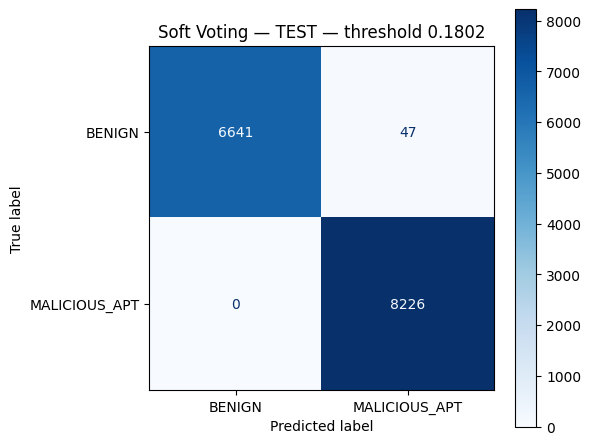

Phát hiện đúng 8,226 tấn công, bỏ sót 0, cảnh báo giả 47, loại đúng 6,641 log benign.


In [9]:
chosen=results[selected_slug]
tn,fp,fn,tp=confusion_matrix(y_test,chosen['pred'],labels=[0,1]).ravel()
fig,ax=plt.subplots(figsize=(6,5))
ConfusionMatrixDisplay.from_predictions(y_test,chosen['pred'],display_labels=['BENIGN','MALICIOUS_APT'],ax=ax,cmap='Blues')
ax.set_title(f'{selected_label} — TEST — threshold {chosen["threshold"]:.4g}'); plt.tight_layout(); plt.show()
print(f'Phát hiện đúng {tp:,} tấn công, bỏ sót {fn:,}, cảnh báo giả {fp:,}, loại đúng {tn:,} log benign.')

## 9. Khoảng bất định của mô hình đã chọn
Bootstrap theo dòng Test chỉ mô tả độ dao động nội bộ; không thay thế validation theo ngày hoặc external validation.

In [10]:
rng=np.random.default_rng(SEED); boot=[]; y_array=y_test.to_numpy(); pred=chosen['pred']; score=chosen['score']
for _ in range(300):
    idx=rng.integers(0,len(y_array),len(y_array))
    if np.unique(y_array[idx]).size<2: continue
    boot.append({'f2':fbeta_score(y_array[idx],pred[idx],beta=2,zero_division=0),'roc_auc':roc_auc_score(y_array[idx],score[idx]),'average_precision':average_precision_score(y_array[idx],score[idx])})
boot=pd.DataFrame(boot); display(pd.DataFrame({'estimate':test_comparison.set_index('model').loc[selected_label,['f2','roc_auc','average_precision']],'ci_2.5%':boot.quantile(.025),'ci_97.5%':boot.quantile(.975)}))

,estimate,ci_2.5%,ci_97.5%
f2,0.998859,0.998525,0.999151
roc_auc,0.999756,0.999536,0.999932
average_precision,0.999750,0.999516,0.999931


## 10. Kiểm tra đủ mô hình trên báo cáo
Bảng, biểu đồ metric, ROC và PR phía trên phải cùng chứa đủ chín mô hình. Một số đường gần như trùng nhau do score rất cao, nhưng legend vẫn liệt kê riêng từng mô hình.

In [11]:
reported_models=[label for _,label,_ in main_specs]
assert len(reported_models)==9 and comparison['model'].nunique()==9 and test_comparison['model'].nunique()==9
display(pd.DataFrame({'order':range(1,10),'model':reported_models}))
print('Đã tổng hợp đủ',len(reported_models),'mô hình.')

,order,model
0,1,Decision Tree
1,2,Naive Bayes
2,3,Rule-Based
3,4,Bagging
4,5,Random Forest
5,6,AdaBoost
6,7,Soft Voting
7,8,Linear SVM
8,9,Logistic Regression


Đã tổng hợp đủ 9 mô hình.


## 11. Kết luận phương pháp
- Train học preprocessing và siêu tham số bằng grouped K-Fold.
- Validation chọn threshold và mô hình theo F2.
- Test chỉ báo cáo sau khi khóa lựa chọn.
- Ensemble chỉ thắng khi Validation chứng minh tốt hơn.
- Không dùng Test để quay lại sửa thiết kế; nếu sửa cần Test mới.

## 12. Giới hạn bắt buộc khi bảo vệ
- Nhãn bắt nguồn từ MITRE/Wazuh rule, không phải ground truth độc lập.
- Dữ liệu Windows APT là môi trường mô phỏng; chưa chứng minh VPN/SSO, web, Linux, brute-force hoặc zero-day.
- Validation hiện chỉ có hai nhóm ngày.
- Score không mặc nhiên là xác suất đã hiệu chỉnh.
- Cần external validation bằng log Wazuh thật của SecuraAI trước production.

## 13. Kết luận cuối
Phần ML chứng minh quy trình xây dựng, đánh giá và tích hợp mô hình vào hệ thống phần mềm. Không tuyên bố mô hình thay thế Wazuh, SOC analyst hoặc LLM; ưu tiên mô hình đáp ứng F2, tải cảnh báo và chi phí triển khai hợp lý.

## Cập nhật pipeline dữ liệu hợp nhất

Notebook này thuộc bộ thí nghiệm SecuraAI mới. Có hai tầng kết quả cần phân biệt:

- **Thí nghiệm giảng dạy 00–10:** so sánh thuật toán trên cùng split Windows-APT để bảo đảm công bằng.
- **Baseline hợp nhất theo từng event:** Windows-APT 2025 + RADAR + log Wazuh đã bộc lộ domain shift khi test trực tiếp.
- **Ứng viên temporal hiện tại:** dùng dữ liệu sự kiện đã chuẩn hóa cùng thống kê hành vi ở các cửa sổ 1, 5, 15 và 60 phút.
- **Luồng triển khai AI:** ML sàng lọc nhanh; chỉ trường hợp vượt ngưỡng Validation mới chuyển sang Foundation-Sec để phân tích ngữ cảnh.
- **Quyết định cuối:** `BENIGN` không tạo alert, `SUSPICIOUS` chờ điều tra, `MALICIOUS` mới tạo hoặc gộp alert. Luồng AI đang bật không sử dụng baseline 7 ngày hay luật cũ để tự quyết định alert.

RADAR bổ sung ground truth ransomware/Sysmon theo từng mẫu thực thi. Log Wazuh hiện tại chỉ là kiểm thử lab và weak-benign; không được trình bày như bằng chứng production. Test, threshold và dữ liệu ngoài miền được giữ tách biệt để giảm leakage.

In [12]:
import pandas as pd

combined_artifact_dir = ROOT / 'artifacts-combined-candidate'
combined_metadata_path = combined_artifact_dir / 'model_metadata.json'
combined_source_report_path = ROOT / 'reports' / 'combined_candidate_by_source.json'
temporal_artifact_dir = ROOT / 'artifacts-temporal-candidate'
temporal_metadata_path = temporal_artifact_dir / 'model_metadata.json'

if combined_metadata_path.exists():
    combined_metadata = json.loads(combined_metadata_path.read_text(encoding='utf-8'))
    display(pd.DataFrame({
        'value': [
            combined_metadata['selectedModel'],
            combined_metadata['lockedThreshold'],
            ', '.join(combined_metadata['datasets']),
            combined_metadata['test']['f2'],
            combined_metadata['test']['precision'],
            combined_metadata['test']['recall'],
        ]
    }, index=['selected_model','locked_threshold','datasets','combined_test_f2','combined_test_precision','combined_test_recall']))
else:
    print('Chưa có artifacts-combined-candidate. Chạy scripts/train_combined_candidate.py trước.')

if temporal_metadata_path.exists():
    temporal_metadata = json.loads(temporal_metadata_path.read_text(encoding='utf-8'))
    display(pd.DataFrame({
        'value': [
            temporal_metadata['selectedModel'], temporal_metadata['lockedThreshold'],
            temporal_metadata['validation']['f2'], temporal_metadata['test']['f2'],
            temporal_metadata['test']['falsePositiveRate'], temporal_metadata['status'],
        ]
    }, index=['temporal_model','temporal_threshold','validation_f2','test_f2','test_fpr','status']))
else:
    print('Chưa có artifacts-temporal-candidate. Chạy scripts/train_temporal_candidate.py trước.')


,value
selected_model,logistic_regression
locked_threshold,0.442104
datasets,"Windows-APT 2025 v4, RADAR v0.0.1-beta"
combined_test_f2,0.994966
combined_test_precision,0.990039
combined_test_recall,0.996205


,value
temporal_model,bagging
temporal_threshold,0.5
validation_f2,1.0
test_f2,1.0
test_fpr,0.0
status,EXPERIMENTAL_CONTROLLED_LAB_ONLY


## Quyết định cuối cho SecuraAI

Kết quả 9 mô hình phía trên là **so sánh thuật toán có kiểm soát trên Windows-APT**. Model dùng thử với SecuraAI hiện tại là ứng viên hợp nhất, được chọn lại trên Validation sau khi thêm RADAR và dữ liệu Wazuh. Vì tập dữ liệu đã thay đổi, không xếp hạng trực tiếp metric của hai thí nghiệm như cùng một cuộc thi.

In [13]:
if combined_metadata_path.exists():
    m = combined_metadata
    final_rows = [
        {'evaluation':'Combined validation', **{k:v for k,v in m['validation'].items() if k != 'confusion_matrix'}},
        {'evaluation':'Combined test', **{k:v for k,v in m['test'].items() if k != 'confusion_matrix'}},
    ]
    display(pd.DataFrame(final_rows).set_index('evaluation'))
    print('CHỌN TRIỂN KHAI THỬ:', m['selectedModel'])
    print('Ngưỡng khóa:', m['lockedThreshold'])
    print('Không gọi score là xác suất:', m['scoreSemantics'])


,threshold,accuracy,balanced_accuracy,precision,recall,f1,f2,roc_auc
evaluation,,,,,,,,
Combined validation,0.442104,0.999242,0.998708,0.999606,0.997560,0.998582,0.997969,0.999811
Combined test,NaN,0.995089,0.995339,0.990039,0.996205,0.993113,0.994966,0.999627


CHỌN TRIỂN KHAI THỬ: logistic_regression
Ngưỡng khóa: 0.4421035321920779
Không gọi score là xác suất: experimental classifier score; not calibrated attack probability


## External validation và ứng viên temporal

Baseline hợp nhất đạt điểm nội bộ cao nhưng chỉ đạt khoảng 49% trên bộ scenario độc lập và báo sai các log Normal khi chạy qua SecuraAI. Vì vậy không chọn baseline này cho alert. Candidate temporal loại các feature nhận diện dataset (`provider`, `location`, raw event ID) và sử dụng thống kê hành vi 1, 5, 15 và 60 phút. Nhãn malicious chỉ bắt đầu tại sự kiện đạt điều kiện hành vi của kịch bản, không gắn nhãn tấn công cho một lần nhập sai đơn lẻ.

In [14]:
temporal_path=ROOT/'artifacts-temporal-candidate'/'model_metadata.json'
if temporal_path.exists():
    temporal=json.loads(temporal_path.read_text(encoding='utf-8'))
    display(pd.DataFrame([
        {'stage':'Validation',**{k:v for k,v in temporal['validation'].items() if k!='confusionMatrix'}},
        {'stage':'Test',**{k:v for k,v in temporal['test'].items() if k!='confusionMatrix'}},
    ]).set_index('stage'))
    print('Candidate:',temporal['selectedModel'],'| threshold:',temporal['lockedThreshold'])
    print('Status:',temporal['status'],'— chưa được phép tự tạo alert')


,threshold,accuracy,precision,recall,f1,f2,falsePositiveRate
stage,,,,,,,
Validation,0.5,1.0,1.0,1.0,1.0,1.0,0.0
Test,NaN,1.0,1.0,1.0,1.0,1.0,0.0


Candidate: bagging | threshold: 0.5
Status: EXPERIMENTAL_CONTROLLED_LAB_ONLY — chưa được phép tự tạo alert


## Kiểm thử trực tiếp qua SecuraAI

Luồng đã kiểm tra hiện tại: `Wazuh → chuẩn hóa → PostgreSQL → context 1/5/15/60 phút → ML sàng lọc → Foundation-Sec xác minh → quyết định alert`.

Ba lần đánh giá dùng run ID mới, không tái sử dụng kết quả cũ:

| Phiên bản | Thay đổi | TN | FP | FN | TP | FPR |
|---|---|---:|---:|---:|---:|---:|
| V1 | Candidate ban đầu | 66 | 8 | 0 | 27 | 10,81% |
| V2 | Thêm burst benign sát ngưỡng | 69 | 5 | 3 | 24 | 6,76% |
| V3 | Thêm operational gate, ngưỡng chọn trên Validation | 74 | 0 | 0 | 27 | 0% |

V3 đạt 100% trên **101 event/15 case kiểm tra biên**, nhưng đây không phải bằng chứng model tổng quát hóa 100%. Toàn bộ dữ liệu PostgreSQL hiện tại cũng là dữ liệu mô phỏng; các case được kiểm soát và cùng ngữ nghĩa ngưỡng với dữ liệu thiết kế. Kết quả nội bộ Test rộng hơn chỉ đạt khoảng 94,33% Accuracy, 84,97% Recall và 3,49% FPR. Trong luồng AI đang bật, ML chỉ sàng lọc: điểm thấp được ghi nhận, điểm vượt ngưỡng mới gọi Foundation-Sec; `BENIGN` không tạo alert, `SUSPICIOUS` chờ điều tra và chỉ `MALICIOUS` mới tạo hoặc gộp alert. Dự án hiện chưa có log Wazuh production được chuyên gia gán nhãn để đánh giá thực tế.

In [15]:
external_files={
    'V1':ROOT/'reports'/'securaai_external_benchmark.json',
    'V2':ROOT/'reports'/'securaai_external_benchmark_v2.json',
    'V3':ROOT/'reports'/'securaai_external_benchmark_v3.json',
}
external_rows=[]
for version,path in external_files.items():
    if path.exists():
        report=json.loads(path.read_text(encoding='utf-8'))
        summary=report['summary']; cm=summary['confusionMatrix']
        external_rows.append({'version':version,**{k:v for k,v in summary.items() if k!='confusionMatrix'},**cm})
if external_rows:
    display(pd.DataFrame(external_rows).set_index('version'))
if external_files['V3'].exists():
    external_v3=json.loads(external_files['V3'].read_text(encoding='utf-8'))
    display(pd.DataFrame(external_v3['byCase']))


,modelVersion,lockedThreshold,runs,events,accuracy,precision,recall,f2,falsePositiveRate,tn,fp,fn,tp
version,,,,,,,,,,,,,
V1,securaai-temporal-synthetic-candidate-v1,0.735188,15,101,0.920792,0.771429,1.000000,0.944056,0.108108,66,8,0,27
V2,securaai-temporal-synthetic-candidate-v1,0.598923,15,101,0.920792,0.827586,0.888889,0.875912,0.067568,69,5,3,24
V3,securaai-temporal-synthetic-candidate-v1,0.352426,15,101,1.000000,1.000000,1.000000,1.000000,0.000000,74,0,0,27


,scenario,burstCount,events,tn,fp,fn,tp
0,AppDenial,8.0,8,8,0,0,0
1,AppDenial,10.0,10,9,0,0,1
2,AppDenial,11.0,11,9,0,0,2
3,AppDenial,15.0,15,9,0,0,6
4,AuthBurst,2.0,2,2,0,0,0
5,AuthBurst,4.0,4,4,0,0,0
6,AuthBurst,5.0,5,4,0,0,1
7,AuthBurst,6.0,6,4,0,0,2
8,AuthBurst,10.0,10,4,0,0,6
9,Normal,NaN,3,3,0,0,0


## Challenge V2 khóa trước khi đánh giá

Challenge V2 được sinh bằng generator độc lập, khóa SHA-256 và đánh giá đúng một lần. File này không bao giờ được đưa vào Train hoặc dùng chọn threshold. Đây là stress test synthetic, không phải accuracy production.

In [16]:
challenge_path=ROOT/'reports'/'challenge_v2_result.json'
if challenge_path.exists():
    challenge=json.loads(challenge_path.read_text(encoding='utf-8'))
    display(pd.Series(challenge['summary'],name='Challenge V2').to_frame())
    challenge_rows=[]
    for scenario,values in challenge['byScenario'].items():
        challenge_rows.append({'scenario':scenario,**{k:v for k,v in values.items() if k!='confusionMatrix'},**values['confusionMatrix']})
    display(pd.DataFrame(challenge_rows).set_index('scenario'))
    print('Không retrain hoặc chỉnh threshold bằng Challenge V2.')


,Challenge V2
events,4750
accuracy,0.905263
precision,0.842105
recall,0.727273
f2,0.747664
falsePositiveRate,0.041096
confusionMatrix,"{'tn': 3500, 'fp': 150, 'fn': 300, 'tp': 800}"


,events,accuracy,precision,recall,f2,falsePositiveRate,tn,fp,fn,tp
scenario,,,,,,,,,,
APP_ALIAS_BURST,650,1.000000,1.0,1.0,1.0,0.000000,450,0,0,200
APP_SUCCESS_AFTER_DENIAL,600,1.000000,1.0,1.0,1.0,0.000000,450,0,0,150
AUTH_ALIAS_BURST,350,0.571429,0.0,0.0,0.0,0.000000,200,0,150,0
AUTH_DISTRIBUTED,350,1.000000,1.0,1.0,1.0,0.000000,200,0,0,150
AUTH_INTERLEAVED_NOISE,350,1.000000,0.0,0.0,0.0,0.000000,350,0,0,0
AUTH_OFFHOURS_SUCCESS,350,1.000000,0.0,0.0,0.0,0.000000,350,0,0,0
AUTH_SLOW_ATTEMPTS,350,1.000000,0.0,0.0,0.0,0.000000,350,0,0,0
AUTH_SPRAY,350,1.000000,1.0,1.0,1.0,0.000000,200,0,0,150
DUPLICATE_TIMESTAMP_AUTH,350,1.000000,1.0,1.0,1.0,0.000000,200,0,0,150


Không retrain hoặc chỉnh threshold bằng Challenge V2.


## Locked robustness challenges V3 and V4

V3 exposed an account-only authentication weakness. Its application short-burst case also had a test-spec conflict: 12 denials were labelled benign although the documented operational boundary is 10. The frozen result is reported unchanged. V4 was created only after candidate v4 was locked, uses a true sub-threshold application burst (8 events), and is never training data.

In [17]:
for version in ('v3','v4'):
    path=ROOT/'reports'/f'challenge_{version}_result.json'
    if not path.exists():
        continue
    result=json.loads(path.read_text(encoding='utf-8'))
    print(result['challengeVersion'],'| model:',result['modelVersion'])
    display(pd.Series(result['summary'],name=result['challengeVersion']).to_frame())
    rows=[]
    for scenario,values in result['byScenario'].items():
        rows.append({'scenario':scenario,**{k:v for k,v in values.items() if k!='confusionMatrix'},**values['confusionMatrix']})
    display(pd.DataFrame(rows).set_index('scenario'))
print('Never retrain or tune a model with any locked challenge.')


challenge-v3 | model: securaai-temporal-synthetic-candidate-v3


,challenge-v3
events,4400
accuracy,0.92
precision,0.862069
recall,0.826087
f2,0.833041
falsePositiveRate,0.046769
confusionMatrix,"{'tn': 3098, 'fp': 152, 'fn': 200, 'tp': 950}"


,events,accuracy,precision,recall,f2,falsePositiveRate,tn,fp,fn,tp
scenario,,,,,,,,,,
APP_MIXED_ALIAS,600,1.000,1.0,1.0,1.0,0.000,450,0,0,150
APP_SHORT_BURST,600,0.750,0.0,0.0,0.0,0.250,450,150,0,0
AUTH_ACCOUNT_ONLY,400,0.500,0.0,0.0,0.0,0.000,200,0,200,0
AUTH_HIGH_VOLUME_NOISE,400,0.995,0.0,0.0,0.0,0.005,398,2,0,0
AUTH_IP_ONLY,400,1.000,1.0,1.0,1.0,0.000,200,0,0,200
AUTH_MIXED_ALIAS,400,1.000,1.0,1.0,1.0,0.000,200,0,0,200
AUTH_SUCCESS_AFTER_MIXED,400,1.000,1.0,1.0,1.0,0.000,200,0,0,200
AUTH_WINDOW_EDGE,400,1.000,0.0,0.0,0.0,0.000,400,0,0,0
VPN_MIXED_ALIAS,400,1.000,1.0,1.0,1.0,0.000,200,0,0,200


challenge-v4 | model: securaai-temporal-synthetic-candidate-v4


,challenge-v4
events,4800
accuracy,0.960625
precision,0.870801
recall,0.962857
f2,0.942921
falsePositiveRate,0.04
confusionMatrix,"{'tn': 3600, 'fp': 150, 'fn': 39, 'tp': 1011}"


,events,accuracy,precision,recall,f2,falsePositiveRate,tn,fp,fn,tp
scenario,,,,,,,,,,
APP_DENIAL_ATTACK,700,1.000000,1.0,1.000,1.000000,0.000000,450,0,0,250
APP_SHORT_BENIGN,400,1.000000,0.0,0.000,0.000000,0.000000,400,0,0,0
APP_STAGGERED_BENIGN,600,1.000000,0.0,0.000,0.000000,0.000000,600,0,0,0
AUTH_ACCOUNT_ONLY_ATTACK,450,1.000000,1.0,1.000,1.000000,0.000000,200,0,0,250
AUTH_ACCOUNT_ONLY_SLOW,450,1.000000,0.0,0.000,0.000000,0.000000,450,0,0,0
AUTH_IP_ONLY_ATTACK,450,0.913333,1.0,0.844,0.871181,0.000000,200,0,39,211
AUTH_MISSING_CONTEXT_NORMAL,350,1.000000,0.0,0.000,0.000000,0.000000,350,0,0,0
AUTH_MIXED_BACKGROUND,550,0.727273,0.0,0.000,0.000000,0.272727,400,150,0,0
VPN_ALIAS_SPRAY,500,1.000000,1.0,1.000,1.000000,0.000000,200,0,0,300


Never retrain or tune a model with any locked challenge.


## Candidate v6: lựa chọn model temporal đúng quy trình

Candidate v6 dùng cùng feature temporal cho bảy thuật toán và Soft Voting. Siêu tham số được chọn bằng 5-Fold `StratifiedGroupKFold` theo session chỉ trên Train; model và threshold được khóa bằng Validation trước khi mở Test. Dữ liệu gồm scenario mô phỏng và 133 Windows Security Event 4625 thật trong lab. Đây **không phải dữ liệu production**.

In [18]:
real_report_path=ROOT/'reports'/'real_windows_auth_lab_v5_live.json'
temporal_metadata_path=ROOT/'artifacts-temporal-candidate'/'model_metadata.json'
if real_report_path.exists():
    real_report=json.loads(real_report_path.read_text(encoding='utf-8'))
    live_cm=real_report['confusionMatrix']
    live_model=real_report['rows'][0]['prediction']['modelVersion'] if real_report.get('rows') else 'missing'
    display(pd.DataFrame({
        'value':[real_report.get('events'),live_cm['tn'],live_cm['fp'],live_cm['fn'],live_cm['tp'],live_model]
    },index=['live_events','tn','fp','fn','tp','model_version']))
if temporal_metadata_path.exists():
    temporal_candidate=json.loads(temporal_metadata_path.read_text(encoding='utf-8'))
    by_origin=temporal_candidate.get('testByOrigin',{})
    rows=[]
    for origin,metric in by_origin.items():
        rows.append({'origin':origin,**{k:v for k,v in metric.items() if k!='confusionMatrix'},**metric.get('confusionMatrix',{})})
    if rows: display(pd.DataFrame(rows).set_index('origin'))
    cv_rows=[]
    for name,result in temporal_candidate['allValidationCandidates'].items():
        cv=temporal_candidate['trainCrossValidation']['candidates'].get(name,{})
        cv_rows.append({'model':name,'mean_cv_f2':cv.get('meanCvF2'),'std_cv_f2':cv.get('stdCvF2'),
                        'validation_f2':result['f2'],'validation_precision':result['precision'],
                        'validation_recall':result['recall'],'threshold':result['threshold']})
    display(pd.DataFrame(cv_rows).sort_values(['validation_f2','mean_cv_f2'],ascending=False))
    print('Candidate:',temporal_candidate['modelVersion'])
    print('Model được chọn:',temporal_candidate['selectedModel'])
    print('Status:',temporal_candidate['status'])
    print('Giới hạn:',temporal_candidate.get('limitations',[]))


,value
live_events,6
tn,4
fp,0
fn,0
tp,2
model_version,securaai-temporal-hybrid-lab-candidate-v5


,accuracy,precision,recall,f1,f2,falsePositiveRate,tn,fp,fn,tp
origin,,,,,,,,,,
SYNTHETIC_SCENARIO,1.0,1.0,1.0,1.0,1.0,0.0,4124,0,0,866
CONTROLLED_REAL_WINDOWS_LAB,1.0,1.0,1.0,1.0,1.0,0.0,17,0,0,8


,model,mean_cv_f2,std_cv_f2,validation_f2,validation_precision,validation_recall,threshold
2,bagging,1.000000,0.000000,1.000000,1.000000,1.000000,0.500000
0,decision_tree,0.999538,0.000924,1.000000,1.000000,1.000000,1.000000
3,random_forest,0.997416,0.002694,0.999781,0.998905,1.000000,0.232453
7,soft_voting,NaN,NaN,0.999781,0.998905,1.000000,0.303298
4,adaboost,1.000000,0.000000,0.997367,1.000000,0.996711,0.511738
6,logistic_regression,0.931282,0.009438,0.977928,0.964440,0.981360,0.333152
5,linear_svm,0.930247,0.007813,0.959708,0.997699,0.950658,0.004550
1,naive_bayes,0.620880,0.028456,0.000000,0.000000,0.000000,1.000000


Candidate: securaai-temporal-hybrid-lab-candidate-v6
Model được chọn: bagging
Status: EXPERIMENTAL_CONTROLLED_LAB_ONLY
Giới hạn: ['trained on controlled synthetic SecuraAI scenarios plus controlled real Windows lab telemetry', 'labels are scenario-manifest ground truth with rule-defined decision boundaries', 'high synthetic metrics are not production accuracy', 'requires past-only five-minute context at inference', 'not approved to create alerts']


## Kiểm thử end-to-end AUTH, VPN/SSO và APP_ACCESS

Benchmark này đọc chính `ml_shadow_prediction` đã được Backend SecuraAI lưu trong PostgreSQL. Mỗi run dùng IP riêng để cửa sổ năm phút không trộn các session độc lập. AUTH/VPN được kiểm tra ở 2, 4, 5, 6 và 10 event; APP_ACCESS ở 8, 10, 11 và 15 event. Đây vẫn là log lab mô phỏng đúng contract, chưa phải log xuất từ VPN/SSO hay ứng dụng production thật.

In [19]:
shadow_report_path=ROOT/'reports'/'securaai_shadow_benchmark_v6_isolated.json'
if shadow_report_path.exists():
    shadow_report=json.loads(shadow_report_path.read_text(encoding='utf-8'))
    summary=shadow_report['summary']
    display(pd.DataFrame({'value':summary}).drop(index=['confusionMatrix'],errors='ignore'))
    display(pd.DataFrame(shadow_report['byCase']))
    print('Confusion matrix:',summary['confusionMatrix'])
    print('Lưu ý: dùng chung IP giữa nhiều account trong 5 phút là password spraying, không phải các session độc lập.')


,value
status,SECURAAI_PERSISTED_ML_SHADOW_EVALUATED
modelVersion,securaai-temporal-hybrid-lab-candidate-v6
runs,15
events,101
accuracy,1.0
precision,1.0
recall,1.0
f2,1.0
falsePositiveRate,0.0


,scenario,burstCount,events,tn,fp,fn,tp
0,AppDenial,10.0,10,9,0,0,1
1,AppDenial,11.0,11,9,0,0,2
2,AppDenial,15.0,15,9,0,0,6
3,AppDenial,8.0,8,8,0,0,0
4,AuthBurst,10.0,10,4,0,0,6
5,AuthBurst,2.0,2,2,0,0,0
6,AuthBurst,4.0,4,4,0,0,0
7,AuthBurst,5.0,5,4,0,0,1
8,AuthBurst,6.0,6,4,0,0,2
9,Normal,NaN,3,3,0,0,0


Confusion matrix: {'tn': 74, 'fp': 0, 'fn': 0, 'tp': 27}
Lưu ý: dùng chung IP giữa nhiều account trong 5 phút là password spraying, không phải các session độc lập.
